# Séance 7 — Introduction à PySpark

**Durée pratique : 3 h** &nbsp;·&nbsp; Ateliers 7.1 à 7.4

## Ce que vous saurez faire à la fin

- démarrer une session Spark locale et charger des données avec un schéma explicite ;
- traduire en PySpark les opérations Pandas que vous maîtrisez déjà ;
- lire un plan d'exécution et comprendre pourquoi rien ne se passe avant l'action ;
- mesurer le point de bascule entre Pandas et Spark, et le justifier.

## Préparation obligatoire avant la séance

```bash
pip install pyspark
python src/generate_data.py --big 5000000   # environ 400 Mo, comptez 3 à 5 minutes
```

Spark exige un environnement Java (JDK 8, 11 ou 17). Vérifiez avec `java -version`.

> **Convention de nommage du module.** Le code est écrit en anglais et suit la PEP 8 :
> fonctions et variables en `snake_case`, constantes en `MAJUSCULES`. Les **noms de colonnes**
> restent en français parce qu'ils viennent de la source : renommer les colonnes d'un fichier
> d'entrée est une transformation comme une autre, elle se décide et se documente, elle ne se
> fait pas par réflexe. Vous rencontrerez cette situation partout en entreprise.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name.lower() in ('notebook', 'notebooks') else Path.cwd()
RAW_DIR = ROOT / 'data' / 'raw'
PROCESSED_DIR = ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

print('Données disponibles :')
for path in sorted(RAW_DIR.glob('*')):
    print(' ', path.name)


# Parquet conserve les types (dates, entiers, catégories) là où le CSV les perd :
# c'est le format à privilégier entre deux étapes d'un pipeline. Repli automatique
# sur le CSV si pyarrow n'est pas installé.
def save_dataset(df, name):
    try:
        path = PROCESSED_DIR / f'{name}.parquet'
        df.to_parquet(path, index=False)
    except ImportError:
        path = PROCESSED_DIR / f'{name}.csv'
        df.to_csv(path, index=False)
        print('(pyarrow absent : repli sur le CSV)')
    print('écrit :', path.name, df.shape)
    return path


def load_dataset(name):
    parquet_path = PROCESSED_DIR / f'{name}.parquet'
    csv_path = PROCESSED_DIR / f'{name}.csv'
    if parquet_path.exists():
        return pd.read_parquet(parquet_path)
    if csv_path.exists():
        return pd.read_csv(csv_path)
    raise FileNotFoundError(f'{name} introuvable : exécutez le notebook précédent')


def dataset_exists(name):
    return ((PROCESSED_DIR / f'{name}.parquet').exists()
            or (PROCESSED_DIR / f'{name}.csv').exists())

Données disponibles :
  capteurs.csv
  clients.csv
  evenements_volumineux.csv
  magasins.csv
  produits.csv
  ventes_brutes.csv
  ventes_extrait.json
  ventes_extrait.xlsx


---
## Atelier 7.1 — Session Spark et schéma explicite (40 min)

### Partie guidée

In [2]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import (DoubleType, IntegerType, LongType, StringType,
                               StructField, StructType, TimestampType)

spark = (SparkSession.builder
         .appName('PMD-M1')
         .master('local[*]')                            # tous les cœurs de la machine
         .config('spark.driver.memory', '4g')
         .config('spark.sql.shuffle.partitions', '16')  # défaut 200, trop pour du local
         .getOrCreate())

spark.sparkContext.setLogLevel('ERROR')
print('Spark', spark.version)
print('Cœurs disponibles :', spark.sparkContext.defaultParallelism)

26/10/20 12:27:00 WARN Utils: Your hostname, MacBook-Air-de-Lucas.local resolves to a loopback address: 127.0.0.1; using 10.45.40.169 instead (on interface en0)
26/10/20 12:27:00 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/20 12:27:00 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/20 12:27:00 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


Spark 3.5.9
Cœurs disponibles : 10


**`spark.sql.shuffle.partitions` à 200 par défaut** est un réglage pensé pour un cluster.
En local il crée 200 tâches minuscules dont l'orchestration coûte plus cher que le calcul.
C'est la première cause de la réputation de lenteur de Spark sur petits volumes.

In [3]:
import time

events_path = str(RAW_DIR / 'evenements_volumineux.csv')

# Méthode 1 : inférence automatique du schéma. Simple, mais Spark lit le fichier
# une première fois uniquement pour deviner les types.
start = time.perf_counter()
events_inferred = spark.read.csv(events_path, header=True, inferSchema=True)
print(f'Inférence : {time.perf_counter() - start:.1f} s')
events_inferred.printSchema()

Inférence : 2.3 s
root
 |-- id_evenement: integer (nullable = true)
 |-- horodatage: timestamp (nullable = true)
 |-- id_utilisateur: integer (nullable = true)
 |-- categorie: string (nullable = true)
 |-- ville: string (nullable = true)
 |-- montant: double (nullable = true)
 |-- duree_s: integer (nullable = true)



In [4]:
# Méthode 2 : schéma explicite. Une seule lecture, et aucune surprise de typage.
EVENTS_SCHEMA = StructType([
    StructField('id_evenement', LongType(), True),
    StructField('horodatage', TimestampType(), True),
    StructField('id_utilisateur', IntegerType(), True),
    StructField('categorie', StringType(), True),
    StructField('ville', StringType(), True),
    StructField('montant', DoubleType(), True),
    StructField('duree_s', IntegerType(), True),
])

start = time.perf_counter()
events = spark.read.csv(events_path, header=True, schema=EVENTS_SCHEMA)
print(f'Schéma explicite : {time.perf_counter() - start:.3f} s')

Schéma explicite : 0.014 s


L'écart est spectaculaire, et il a une explication simple : avec un schéma explicite,
**rien n'a encore été lu**. Spark s'est contenté d'enregistrer une intention.

In [5]:
# La preuve : count() est une ACTION, elle déclenche le calcul réel
start = time.perf_counter()
n_rows = events.count()
print(f'{n_rows} lignes comptées en {time.perf_counter() - start:.1f} s')

5000000 lignes comptées en 0.3 s


### Partie autonome

In [6]:
# Q1. Charger le fichier ventes_brutes.csv dans Spark avec un schéma explicite.
#     Attention : prix_unitaire contient du texte pour une partie des lignes.
#     Quel type déclarez-vous, et pourquoi ?

# TODO
# prix_unitaire est déclaré en STRING : une partie des lignes contient '129,12 EUR'.
# Déclaré en DoubleType, Spark (mode PERMISSIVE par défaut) remplacerait ces valeurs
# par null SANS AUCUNE ERREUR : on perdrait des prix silencieusement. On lit donc le
# texte tel quel, et la conversion se fera explicitement au nettoyage (Q2).
# Même raisonnement pour date_commande (cinq formats coexistent) et pour les
# identifiants, qui sont des clés textuelles (C02300, P0009, M05) et non des nombres.
SALES_SCHEMA = StructType([
    StructField('id_commande', StringType(), True),
    StructField('date_commande', StringType(), True),
    StructField('id_client', StringType(), True),
    StructField('id_produit', StringType(), True),
    StructField('id_magasin', StringType(), True),
    StructField('quantite', IntegerType(), True),
    StructField('prix_unitaire', StringType(), True),
    StructField('remise_pct', DoubleType(), True),
    StructField('canal', StringType(), True),
    StructField('statut', StringType(), True),
    StructField('ville_livraison', StringType(), True),
])

sales_raw = spark.read.csv(str(RAW_DIR / 'ventes_brutes.csv'), header=True, schema=SALES_SCHEMA)
sales_raw.printSchema()
print('Lignes :', sales_raw.count())

# Ce qu'on aurait perdu en déclarant prix_unitaire en double :
n_text_prices = sales_raw.filter(F.col('prix_unitaire').cast('double').isNull()
                                 & F.col('prix_unitaire').isNotNull()).count()
print('Prix textuels qui seraient devenus null en DoubleType :', n_text_prices)

root
 |-- id_commande: string (nullable = true)
 |-- date_commande: string (nullable = true)
 |-- id_client: string (nullable = true)
 |-- id_produit: string (nullable = true)
 |-- id_magasin: string (nullable = true)
 |-- quantite: integer (nullable = true)
 |-- prix_unitaire: string (nullable = true)
 |-- remise_pct: double (nullable = true)
 |-- canal: string (nullable = true)
 |-- statut: string (nullable = true)
 |-- ville_livraison: string (nullable = true)

Lignes : 17609
Prix textuels qui seraient devenus null en DoubleType : 1230


---
## Atelier 7.2 — Rejouer le nettoyage en PySpark (55 min)

### Partie guidée : le dictionnaire de traduction

| Pandas | PySpark |
|---|---|
| `df[df.a > 5]` | `df.filter(F.col('a') > 5)` |
| `df['b'] = df['a'] * 2` | `df.withColumn('b', F.col('a') * 2)` |
| `df[['a','b']]` | `df.select('a', 'b')` |
| `df.rename(columns={'a':'c'})` | `df.withColumnRenamed('a', 'c')` |
| `df.groupby('a')['b'].sum()` | `df.groupBy('a').agg(F.sum('b'))` |
| `df.drop_duplicates()` | `df.dropDuplicates()` |
| `df.dropna(subset=['a'])` | `df.na.drop(subset=['a'])` |
| `df.fillna({'a': 0})` | `df.na.fill({'a': 0})` |
| `df.sort_values('a')` | `df.orderBy('a')` |
| `df.head(5)` | `df.show(5)` ou `df.limit(5).toPandas()` |

**La différence de fond n'est pas syntaxique.** En Pandas, chaque ligne s'exécute
immédiatement. En Spark, elle s'ajoute à un plan qui ne sera évalué qu'à la première action.

In [7]:
clean_events = (events
                .filter(F.col('montant') > 0)
                .filter(F.col('duree_s').between(1, 7200))
                .withColumn('ville', F.lower(F.trim(F.col('ville'))))
                .withColumn('jour', F.to_date('horodatage'))
                .withColumn('heure', F.hour('horodatage'))
                .withColumn('est_weekend', F.dayofweek('horodatage').isin([1, 7]))
                .withColumn('tranche_montant',
                            F.when(F.col('montant') < 30, 'faible')
                             .when(F.col('montant') < 100, 'moyen')
                             .otherwise('eleve'))
                .dropDuplicates(['id_evenement']))

print('Aucun calcul lancé à ce stade.')
clean_events.printSchema()

Aucun calcul lancé à ce stade.
root
 |-- id_evenement: long (nullable = true)
 |-- horodatage: timestamp (nullable = true)
 |-- id_utilisateur: integer (nullable = true)
 |-- categorie: string (nullable = true)
 |-- ville: string (nullable = true)
 |-- montant: double (nullable = true)
 |-- duree_s: integer (nullable = true)
 |-- jour: date (nullable = true)
 |-- heure: integer (nullable = true)
 |-- est_weekend: boolean (nullable = true)
 |-- tranche_montant: string (nullable = false)



In [8]:
# Le plan d'exécution : ce que Spark VA faire, et comment Catalyst l'a réorganisé
clean_events.explain(mode='formatted')

== Physical Plan ==
AdaptiveSparkPlan (9)
+- SortAggregate (8)
   +- Sort (7)
      +- Exchange (6)
         +- SortAggregate (5)
            +- Sort (4)
               +- Project (3)
                  +- Filter (2)
                     +- Scan csv  (1)


(1) Scan csv 
Output [7]: [id_evenement#31L, horodatage#32, id_utilisateur#33, categorie#34, ville#35, montant#36, duree_s#37]
Batched: false
Location: InMemoryFileIndex [file:/Users/lucas/TP_Données_Coda/data/raw/evenements_volumineux.csv]
PushedFilters: [IsNotNull(montant), IsNotNull(duree_s), GreaterThan(montant,0.0), GreaterThanOrEqual(duree_s,1), LessThanOrEqual(duree_s,7200)]
ReadSchema: struct<id_evenement:bigint,horodatage:timestamp,id_utilisateur:int,categorie:string,ville:string,montant:double,duree_s:int>

(2) Filter
Input [7]: [id_evenement#31L, horodatage#32, id_utilisateur#33, categorie#34, ville#35, montant#36, duree_s#37]
Condition : ((((isnotnull(montant#36) AND isnotnull(duree_s#37)) AND (montant#36 > 0.0)) AND (dur

Repérez dans le plan la remontée des filtres au plus près de la lecture du fichier
(*predicate pushdown*) et la sélection des seules colonnes utiles (*column pruning*).
Vous n'avez pas demandé ces optimisations : Catalyst les a déduites de votre plan.
C'est la contrepartie de l'évaluation paresseuse.

### Partie autonome

In [9]:
# Q2. Écrire l'équivalent PySpark du nettoyage de la séance 3 sur les ventes :
#     conversion du prix textuel, normalisation des colonnes texte, suppression des
#     doublons, parsing de la date, calcul du montant.
#     Indices : F.regexp_replace, F.to_timestamp, F.coalesce.

# TODO
# Les formats de date invalides doivent renvoyer null (et non lever une erreur) pour
# pouvoir essayer plusieurs formats à la suite avec coalesce.
spark.conf.set('spark.sql.legacy.timeParserPolicy', 'CORRECTED')

TEXT_COLUMNS = ['canal', 'statut', 'ville_livraison']   # jamais les identifiants
DATE_FORMATS = ['yyyy/MM/dd HH:mm', 'yyyy-MM-dd', 'dd/MM/yyyy', 'dd-MM-yyyy', 'dd MMM yyyy']
ACCENTS, NO_ACCENTS = 'àâäáãéèêëíìîïóòôöõúùûüçñ', 'aaaaaeeeeiiiiooooouuuucn'


def normalize_text_spark(column):
    """Casse, espaces et accents, comme normalize_text de la séance 3."""
    text = F.lower(F.trim(F.col(column)))
    text = F.translate(text, ACCENTS, NO_ACCENTS)
    return F.regexp_replace(text, r'\s+', ' ')


def clean_sales_spark(df):
    """Équivalent PySpark de clean_sales (séance 3), dans le même ordre."""
    # 1. prix : '129,12 EUR' -> 129.12
    price = F.regexp_replace(F.trim(F.col('prix_unitaire')), ' EUR', '')
    df = df.withColumn('prix_unitaire', F.regexp_replace(price, ',', '.').cast('double'))
    # 2. colonnes texte descriptives
    for column in TEXT_COLUMNS:
        df = df.withColumn(column, normalize_text_spark(column))
    # 3. doublons stricts
    df = df.dropDuplicates()
    # 4. date : on essaie chaque format, le premier qui réussit l'emporte
    df = df.withColumn('date_commande',
                       F.coalesce(*[F.to_timestamp('date_commande', fmt) for fmt in DATE_FORMATS]))
    df = df.na.drop(subset=['date_commande'])
    # 5. remise manquante = pas de remise ; 6. quantités négatives impossibles
    df = df.na.fill({'remise_pct': 0}).filter(F.col('quantite') >= 0)
    # 7. montant
    return df.withColumn('montant', F.col('quantite') * F.col('prix_unitaire')
                         * (1 - F.col('remise_pct') / 100))


sales_spark = clean_sales_spark(sales_raw).cache()

# Contrôle : on doit retrouver le résultat Pandas de la séance 3
sales_pandas = load_dataset('ventes_nettoyees')
spark_totals = sales_spark.agg(F.count('*').alias('n'), F.sum('montant').alias('ca')).first()
print(f"Lignes  : Spark {spark_totals['n']} | Pandas {len(sales_pandas)}")
print(f"CA      : Spark {spark_totals['ca']:,.2f} | Pandas {sales_pandas['montant'].sum():,.2f}")
print('Prix encore non convertis :', sales_spark.filter(F.col('prix_unitaire').isNull()).count())
print('Modalités de canal        :', [row['canal'] for row in sales_spark.select('canal').distinct().collect()])
sales_spark.show(5, truncate=False)

Lignes  : Spark 16992 | Pandas 16992
CA      : Spark 42,715,846.14 | Pandas 42,715,846.14
Prix encore non convertis : 0
Modalités de canal        : ['boutique', 'telephone', 'web']


+-----------+-------------------+---------+----------+----------+--------+-------------+----------+---------+--------+---------------+-----------------+
|id_commande|date_commande      |id_client|id_produit|id_magasin|quantite|prix_unitaire|remise_pct|canal    |statut  |ville_livraison|montant          |
+-----------+-------------------+---------+----------+----------+--------+-------------+----------+---------+--------+---------------+-----------------+
|CMD0006856 |2024-08-30 00:00:00|C02516   |P0005     |M99       |2       |129.12       |0.0       |telephone|livre   |paris          |258.24           |
|CMD0002907 |2023-03-26 14:01:00|C01197   |P0015     |M04       |2       |489.25       |15.0      |web      |annule  |marseille      |831.725          |
|CMD0016240 |2023-11-22 00:00:00|C01093   |P0038     |M05       |1       |607.7        |20.0      |boutique |livre   |lyon           |486.1600000000001|
|CMD0016527 |2024-01-08 00:00:00|C02187   |P0027     |M05       |2       |552.38  

**Q3.** Dans votre version PySpark, quelle opération du nettoyage Pandas avez-vous eu le
plus de mal à traduire ? Pourquoi ?

*Votre réponse :*

Le **parsing des dates** a été le plus difficile à traduire. En Pandas, une seule ligne
(`pd.to_datetime(..., format='mixed', dayfirst=True)`) infère le format ligne par ligne.
Spark n'a pas d'équivalent : il faut **lister explicitement chaque format** présent dans la
colonne (`yyyy/MM/dd HH:mm`, `yyyy-MM-dd`, `dd/MM/yyyy`, `dd-MM-yyyy`, `dd MMM yyyy`), les
essayer un à un avec `F.coalesce`, et régler `spark.sql.legacy.timeParserPolicy` pour qu'un
format qui ne correspond pas renvoie `null` au lieu de lever une erreur. L'ordre des formats
compte (ambiguïté `05/03/2024`), et un format oublié se traduit par des lignes supprimées en
silence : d'où le contrôle du nombre de lignes et du CA face au résultat Pandas.
La **suppression des accents** posait le même type de problème : Spark n'a pas de
normalisation Unicode, il a fallu passer par `F.translate` avec une table de correspondance.

---
## Atelier 7.3 — Agrégations, jointures et partitions (45 min)

In [10]:
summary = (clean_events
           .groupBy('ville', 'categorie')
           .agg(F.count('*').alias('nb_evenements'),
                F.round(F.sum('montant'), 2).alias('ca_total'),
                F.round(F.avg('montant'), 2).alias('montant_moyen'),
                F.expr('percentile_approx(montant, 0.5)').alias('montant_median'),
                F.countDistinct('id_utilisateur').alias('utilisateurs_uniques'))
           .orderBy(F.desc('ca_total')))

summary.show(10, truncate=False)

+---------+------------+-------------+-------------+-------------+--------------+--------------------+
|ville    |categorie   |nb_evenements|ca_total     |montant_moyen|montant_median|utilisateurs_uniques|
+---------+------------+-------------+-------------+-------------+--------------+--------------------+
|nantes   |Mobilier    |156977       |1.038196894E7|66.14        |58.96         |129689              |
|toulouse |Informatique|156790       |1.036602739E7|66.11        |58.98         |129742              |
|bordeaux |Audio       |156617       |1.035499727E7|66.12        |59.08         |129570              |
|bordeaux |Accessoire  |156297       |1.034810469E7|66.21        |58.95         |129182              |
|marseille|Informatique|156575       |1.034584878E7|66.08        |58.88         |129372              |
|lille    |Informatique|156624       |1.034475666E7|66.05        |58.79         |129445              |
|toulouse |Audio       |156692       |1.03373143E7 |65.97        |58.89  

`percentile_approx` calcule une médiane **approchée**. Une médiane exacte imposerait de
trier l'intégralité des données sur l'ensemble des machines, ce qui coûte infiniment plus
cher. Sur des volumes de cet ordre, l'approximation est indiscernable du résultat exact.

In [11]:
# Écriture partitionnée : chaque valeur de partition devient un sous-dossier
import os
output_path = str(PROCESSED_DIR / 'evenements_spark')

(clean_events
 .select('id_evenement', 'jour', 'ville', 'categorie', 'montant', 'duree_s')
 .write.mode('overwrite')
 .partitionBy('categorie')
 .parquet(output_path))

print('Écrit dans', output_path)
for folder in sorted(os.listdir(output_path))[:6]:
    print(' ', folder)

Écrit dans /Users/lucas/TP_Données_Coda/data/processed/evenements_spark
  ._SUCCESS.crc
  _SUCCESS
  categorie=Accessoire
  categorie=Audio
  categorie=Informatique
  categorie=Mobilier


Le partitionnement sur disque permet à une lecture filtrée sur `categorie` de ne toucher
que le sous-dossier concerné. Choisissez la clé de partitionnement en fonction des filtres
les plus fréquents, et évitez les clés de forte cardinalité : mille partitions de dix lignes
sont pires que pas de partitionnement du tout.

In [12]:
# Q4. Reproduire en PySpark l'assemblage de la séance 6 : joindre les ventes
#     aux produits et aux magasins, puis produire le chiffre d'affaires par région
#     et par catégorie. Comparez le résultat à celui obtenu en Pandas.

# TODO
products_spark = spark.read.csv(str(RAW_DIR / 'produits.csv'), header=True, inferSchema=True)
stores_spark = spark.read.csv(str(RAW_DIR / 'magasins.csv'), header=True, inferSchema=True)

sales_joined = (sales_spark
                .join(products_spark.select('id_produit', 'categorie'), on='id_produit', how='left')
                .join(stores_spark.select('id_magasin', 'region'), on='id_magasin', how='left')
                .na.fill({'categorie': 'inconnu'}))   # produit orphelin P9999, comme en séance 6

# Contrôle de cardinalité, comme validate='many_to_one' en Pandas
assert sales_joined.count() == sales_spark.count(), 'la jointure a modifié le nombre de lignes'

revenue_spark = (sales_joined
                 .groupBy('region', 'categorie')
                 .agg(F.round(F.sum('montant'), 2).alias('ca'))
                 .orderBy('region', 'categorie'))
revenue_spark.show(50, truncate=False)

# Même calcul en Pandas, à partir du jeu nettoyé de la séance 3
products_pd = pd.read_csv(RAW_DIR / 'produits.csv')
stores_pd = pd.read_csv(RAW_DIR / 'magasins.csv')
revenue_pandas = (sales_pandas
                  .merge(products_pd[['id_produit', 'categorie']], on='id_produit',
                         how='left', validate='many_to_one')
                  .merge(stores_pd[['id_magasin', 'region']], on='id_magasin',
                         how='left', validate='many_to_one')
                  .fillna({'categorie': 'inconnu'})
                  .groupby(['region', 'categorie'], as_index=False)['montant'].sum()
                  .rename(columns={'montant': 'ca'}))

check = revenue_spark.toPandas().merge(revenue_pandas, on=['region', 'categorie'],
                                       how='outer', suffixes=('_spark', '_pandas'), indicator=True)
print('Groupes Spark / Pandas      :', revenue_spark.count(), '/', len(revenue_pandas))
print('Groupes présents d\'un seul côté :', (check['_merge'] != 'both').sum())
print('Écart maximal de CA (EUR)   :', round((check['ca_spark'] - check['ca_pandas']).abs().max(), 2))

+--------------------+------------+----------+
|region              |categorie   |ca        |
+--------------------+------------+----------+
|Auvergne-Rhone-Alpes|Accessoire  |553065.74 |
|Auvergne-Rhone-Alpes|Audio       |788067.72 |
|Auvergne-Rhone-Alpes|Informatique|3099500.65|
|Auvergne-Rhone-Alpes|Mobilier    |799324.42 |
|Auvergne-Rhone-Alpes|inconnu     |18691.99  |
|Centre-Val de Loire |Accessoire  |850774.19 |
|Centre-Val de Loire |Audio       |2087229.79|
|Centre-Val de Loire |Informatique|2704922.47|
|Centre-Val de Loire |Mobilier    |1905048.64|
|Centre-Val de Loire |inconnu     |6919.75   |
|Grand Est           |Accessoire  |1414436.56|
|Grand Est           |Audio       |591180.66 |
|Grand Est           |Informatique|3500379.43|
|Grand Est           |Mobilier    |389993.01 |
|Grand Est           |inconnu     |2950.41   |
|Hauts-de-France     |Accessoire  |1800574.26|
|Hauts-de-France     |Audio       |596784.21 |
|Hauts-de-France     |Informatique|1725614.47|
|Hauts-de-Fra

Groupes Spark / Pandas      : 45 / 45
Groupes présents d'un seul côté : 0
Écart maximal de CA (EUR)   : 0.01


In [13]:
# Q5. Exécuter .explain() sur votre jointure. Repérez le type de jointure choisi
#     par Spark (BroadcastHashJoin ou SortMergeJoin) et expliquez ce choix
#     au regard de la taille des tables.

# TODO
sales_joined.explain()

physical_plan = sales_joined._jdf.queryExecution().executedPlan().toString()
for join_type in ['BroadcastHashJoin', 'SortMergeJoin', 'ShuffledHashJoin']:
    print(f'{join_type:<18} : {physical_plan.count(join_type)} occurrence(s)')
print('Seuil de broadcast :', spark.conf.get('spark.sql.autoBroadcastJoinThreshold'))
# Spark choisit un BroadcastHashJoin pour les deux jointures : produits (39 lignes) et
# magasins (9 lignes) pèsent quelques kilo-octets, très en dessous du seuil de 10 Mo
# (spark.sql.autoBroadcastJoinThreshold). Spark copie donc ces petites tables en entier
# sur chaque exécuteur et joint chaque partition des ventes localement, sans redistribuer
# (shuffle) la grande table. Un SortMergeJoin n'apparaîtrait que si les DEUX tables
# dépassaient ce seuil : il faudrait alors trier et redistribuer les deux côtés par clé,
# ce qui est bien plus coûteux.

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [id_magasin#61, id_produit#60, id_commande#57, date_commande#272, id_client#59, quantite#62, prix_unitaire#224, remise_pct#306, canal#236, statut#248, ville_livraison#260, montant#318, coalesce(categorie#2142, inconnu) AS categorie#2224, region#2170]
   +- BroadcastHashJoin [id_magasin#61], [id_magasin#2167], LeftOuter, BuildRight, false
      :- Project [id_produit#60, id_commande#57, date_commande#272, id_client#59, id_magasin#61, quantite#62, prix_unitaire#224, remise_pct#306, canal#236, statut#248, ville_livraison#260, montant#318, categorie#2142]
      :  +- BroadcastHashJoin [id_produit#60], [id_produit#2140], LeftOuter, BuildRight, false
      :     :- InMemoryTableScan [id_commande#57, date_commande#272, id_client#59, id_produit#60, id_magasin#61, quantite#62, prix_unitaire#224, remise_pct#306, canal#236, statut#248, ville_livraison#260, montant#318]
      :     :     +- InMemoryRelation [id_commande#57, date_co

---
## Atelier 7.4 — Où se situe le point de bascule (40 min)

C'est l'atelier dont vous devrez rendre compte en soutenance. La question *pourquoi avoir
utilisé Spark ici ?* appelle une réponse chiffrée, pas une intuition.

In [14]:
def benchmark_pandas(path, n_rows):
    start = time.perf_counter()
    df = pd.read_csv(path, nrows=n_rows)
    result = (df[df['montant'] > 0]
              .groupby(['ville', 'categorie'])
              .agg(nb=('id_evenement', 'count'), ca=('montant', 'sum')))
    duration = time.perf_counter() - start
    memory_mb = df.memory_usage(deep=True).sum() / 1024 ** 2
    del df
    return duration, memory_mb, len(result)


def benchmark_spark(path, n_rows):
    start = time.perf_counter()
    df = spark.read.csv(path, header=True, schema=EVENTS_SCHEMA).limit(n_rows)
    result = (df.filter(F.col('montant') > 0)
              .groupBy('ville', 'categorie')
              .agg(F.count('*').alias('nb'), F.sum('montant').alias('ca')))
    n_groups = result.count()
    return time.perf_counter() - start, None, n_groups

In [15]:
SAMPLE_SIZES = [50_000, 250_000, 1_000_000, 3_000_000]
measurements = []

for n_rows in SAMPLE_SIZES:
    pandas_duration, memory_mb, _ = benchmark_pandas(events_path, n_rows)
    spark_duration, _, _ = benchmark_spark(events_path, n_rows)
    measurements.append({
        'lignes': n_rows,
        'pandas_s': round(pandas_duration, 2),
        'spark_s': round(spark_duration, 2),
        'memoire_pandas_Mo': round(memory_mb, 1),
        'rapport': round(pandas_duration / spark_duration, 2),
    })
    print(measurements[-1])

comparison = pd.DataFrame(measurements)
comparison

{'lignes': 50000, 'pandas_s': 0.03, 'spark_s': 0.27, 'memoire_pandas_Mo': np.float64(4.3), 'rapport': 0.1}


{'lignes': 250000, 'pandas_s': 0.12, 'spark_s': 0.42, 'memoire_pandas_Mo': np.float64(21.6), 'rapport': 0.29}


{'lignes': 1000000, 'pandas_s': 0.46, 'spark_s': 0.75, 'memoire_pandas_Mo': np.float64(86.4), 'rapport': 0.61}


{'lignes': 3000000, 'pandas_s': 1.23, 'spark_s': 0.93, 'memoire_pandas_Mo': np.float64(259.3), 'rapport': 1.33}


,lignes,pandas_s,spark_s,memoire_pandas_Mo,rapport
0,50000,0.03,0.27,4.3,0.10
1,250000,0.12,0.42,21.6,0.29
2,1000000,0.46,0.75,86.4,0.61
3,3000000,1.23,0.93,259.3,1.33


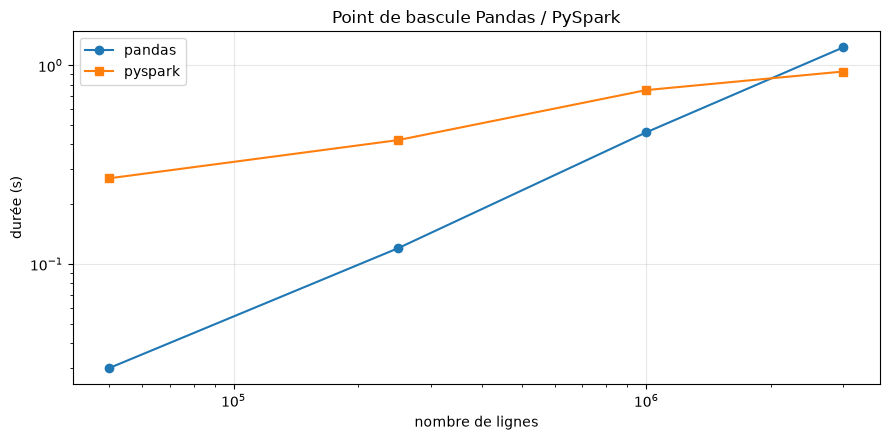

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(comparison['lignes'], comparison['pandas_s'], marker='o', label='pandas')
ax.plot(comparison['lignes'], comparison['spark_s'], marker='s', label='pyspark')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('nombre de lignes')
ax.set_ylabel('durée (s)')
ax.set_title('Point de bascule Pandas / PySpark')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interprétation attendue

Sur une machine unique, **Pandas gagne presque toujours en durée brute**. Spark paie un coût
fixe de démarrage et de coordination que le parallélisme local ne compense pas.

L'intérêt de Spark n'est donc pas la vitesse à cette échelle, mais :

- la capacité à traiter un volume qui ne tient pas en mémoire ;
- la possibilité de passer du local au cluster sans réécrire le code ;
- la lecture sélective de données partitionnées, sans charger le reste.

**Répondre « j'ai utilisé Spark parce que c'est plus rapide » en soutenance est une réponse
fausse et sera sanctionnée.** La bonne réponse porte sur le volume, la mémoire disponible
et la trajectoire du projet.

In [17]:
# Q6. Compléter le tableau : à partir de quel volume Pandas dépasse-t-il la mémoire
#     disponible sur VOTRE machine ? Estimez-le à partir de la colonne memoire_pandas_Mo
#     et de la RAM dont vous disposez. Écrivez la valeur et le raisonnement.

# TODO
import psutil

total_ram_gb = psutil.virtual_memory().total / 1024 ** 3
available_ram_gb = psutil.virtual_memory().available / 1024 ** 3

# Mémoire par ligne, mesurée sur le plus grand échantillon
largest = comparison.iloc[-1]
bytes_per_row = largest['memoire_pandas_Mo'] * 1024 ** 2 / largest['lignes']

# Pandas a besoin de bien plus que la taille du DataFrame : un filtre ou un groupby crée
# des copies intermédiaires. On retient la règle usuelle d'un facteur 3 entre la taille
# du DataFrame et la mémoire de travail nécessaire, et on ne compte que la RAM
# réellement disponible (le système et les autres applications en occupent une partie).
WORKING_FACTOR = 3
max_rows = available_ram_gb * 1024 ** 3 / (bytes_per_row * WORKING_FACTOR)
n_events = events.count()          # n_rows a été réutilisé par la boucle de benchmark
full_file_gb = bytes_per_row * n_events / 1024 ** 3

print(f'RAM totale de la machine     : {total_ram_gb:.1f} Go')
print(f'RAM disponible à cet instant : {available_ram_gb:.1f} Go')
print(f'Mémoire Pandas par ligne     : {bytes_per_row:.0f} octets')
print(f'Fichier complet ({n_events:,} lignes) en Pandas : {full_file_gb:.2f} Go'.replace(',', ' '))
print(f'Limite estimée pour Pandas   : ~{max_rows / 1e6:.0f} millions de lignes'
      f' (~{max_rows * bytes_per_row / 1024 ** 3:.1f} Go de DataFrame)')
# Raisonnement : la mémoire croît linéairement avec le nombre de lignes (environ 90 octets
# par ligne ici). Avec le facteur 3 de mémoire de travail, Pandas reste confortable tant
# que le DataFrame ne dépasse pas un tiers de la RAM disponible. Le fichier complet de
# 5 millions de lignes tient donc largement en Pandas sur cette machine ; c'est à partir
# de plusieurs dizaines de millions de lignes (ordre de grandeur affiché ci-dessus, qui
# varie selon la RAM libre au moment de la mesure) que Pandas sature et que Spark devient
# indispensable, car il traite les données par partitions sans tout charger en mémoire.

RAM totale de la machine     : 24.0 Go
RAM disponible à cet instant : 7.7 Go
Mémoire Pandas par ligne     : 91 octets
Fichier complet (5 000 000 lignes) en Pandas : 0.42 Go
Limite estimée pour Pandas   : ~30 millions de lignes (~2.6 Go de DataFrame)


### Justification : quelles étapes en Spark, quelles étapes en Pandas

**Mesures sur ma machine (24 Go de RAM, 10 cœurs).** Pandas est environ dix fois plus rapide
que Spark sur 50 000 lignes (0,03 s contre 0,27 s) : Spark paie un coût fixe de planification
et de coordination. L'écart se resserre avec le volume, et Spark ne passe devant qu'autour de
3 millions de lignes (1,23 s contre 0,93 s), avec un gain modeste. La vitesse n'est donc
**pas** l'argument : à cette échelle, les deux outils restent du même ordre de grandeur.

**Choix pour le projet :**

- **Ventes, clients, produits, magasins (quelques milliers de lignes, quelques Mo) → Pandas.**
  Tout tient en mémoire avec une marge énorme, Pandas répond instantanément, et le code des
  séances 3 à 6 (nettoyage, encodage, modèle en étoile) est déjà écrit et testé.
- **Journal d'événements (5 millions de lignes, 300 Mo de CSV) → Spark pour l'ingestion,
  le nettoyage et l'écriture en Parquet partitionné.** Le fichier tient encore en mémoire
  aujourd'hui, mais c'est une source qui **s'accumule** : chaque mois ajoute des millions de
  lignes. D'après l'estimation de la question 6, Pandas atteindrait la limite de la RAM
  disponible vers 30 millions de lignes environ, soit quelques mois d'historique.
  Spark traite les données par partitions sans tout charger, et le même code passera d'une
  machine à un cluster sans réécriture. Le partitionnement par `categorie` permet en outre
  aux analyses suivantes de ne lire que le sous-dossier utile.
- **Résultats agrégés (quelques dizaines de lignes) → retour en Pandas** avec `toPandas()`,
  pour les graphiques et les exports vers l'outil de BI.

En résumé, Spark est retenu pour **le volume et sa trajectoire de croissance**, pas pour
la vitesse.

In [18]:
spark.stop()
print('Session fermée.')

Session fermée.


---
## Livrable de la séance

- un script `src/spark_pipeline.py` autonome, exécutable par `spark-submit`, produisant
  un Parquet partitionné ;
- le tableau comparatif chiffré Pandas / PySpark et le graphique associé ;
- un paragraphe écrit justifiant, pour votre projet, le choix de traiter telle étape en
  Spark plutôt qu'en Pandas.